In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded.keys())))

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Saving cwc_reservoir_storage_2026-10-29.csv to cwc_reservoir_storage_2026-10-29.csv
Dataset shape: (178, 18)
Columns: ['sno', 'reservoir', 'state', 'irr_cca_th_ha', 'hydel_mw', 'frl_m', 'live_cap_frl_bcm', 'date', 'current_level_m', 'current_storage_bcm', 'current_pct_of_frl_cap', 'last_year_level_m', 'last_year_storage_bcm', 'last_year_pct_of_frl_cap', 'normal_storage_bcm', 'normal_pct_of_frl_cap', 'pct_this_yr_to_last_yr', 'pct_this_yr_to_normal']


In [4]:
target_column = "current_storage_bcm"

feature_columns = [
    "live_cap_frl_bcm",
    "current_level_m",
    "last_year_storage_bcm",
    "normal_storage_bcm"
]

# Keep the required columns
data = df[feature_columns + [target_column]].copy()

# Convert columns to numeric values
for col in feature_columns + [target_column]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove rows where the target is missing
data = data.dropna(subset=[target_column]).reset_index(drop=True)

X = data[feature_columns]
y = data[target_column]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))



Training rows: 142
Testing rows: 36


In [6]:
models = {
    "Linear Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        LinearRegression()
    ),

    "Polynomial Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    ),

    "Ridge Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "KNN Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5)
    )
}

In [7]:
results = []
predictions = pd.DataFrame({
    "Actual_Storage_BCM": y_test.to_numpy()
}, index=y_test.index)

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict test-set values
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    predictions[name + "_Prediction"] = y_pred

    print(f"\n--- {name} ---")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE:  {mae:.4f}")
    print(f"R2:   {r2:.4f}")


--- Linear Regression ---
RMSE: 0.3512
MAE:  0.1508
R2:   0.7512

--- Polynomial Regression ---
RMSE: 0.2832
MAE:  0.1866
R2:   0.8383

--- Ridge Regression ---
RMSE: 0.2762
MAE:  0.1331
R2:   0.8461

--- KNN Regression ---
RMSE: 0.2137
MAE:  0.1323
R2:   0.9079


In [8]:
results_df = pd.DataFrame(results)

# Sort models by RMSE (lower is better)
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

results_df.to_csv("model_comparison.csv", index=False)

predictions = predictions.sort_index()
predictions.to_csv("model_predictions.csv", index_label="Original_Row_Index")


In [9]:
print("\nMODEL COMPARISON")
display(results_df.round(4))

print("\nMODEL PREDICTIONS")
display(predictions.head(10).round(4))


MODEL COMPARISON


,Model,RMSE,MAE,R2
3,KNN Regression,0.2137,0.1323,0.9079
2,Ridge Regression,0.2762,0.1331,0.8461
1,Polynomial Regression,0.2832,0.1866,0.8383
0,Linear Regression,0.3512,0.1508,0.7512



MODEL PREDICTIONS


,Actual_Storage_BCM,Linear Regression_Prediction,Polynomial Regression_Prediction,Ridge Regression_Prediction,KNN Regression_Prediction
9,0.323,0.2496,0.2131,0.2314,0.2858
12,1.193,1.2868,1.0099,1.2769,1.0908
15,0.664,0.5969,0.5175,0.5488,0.4146
16,0.864,0.7901,0.7159,0.7273,0.5360
18,0.729,0.6739,0.4290,0.6998,0.6136
19,0.126,0.1029,0.0726,0.1758,0.1784
24,0.086,0.1587,0.0735,0.1904,0.1936
29,0.322,0.2181,0.1915,0.2499,0.2852
30,0.225,0.1485,0.1575,0.1613,0.1230
31,0.629,0.5470,0.5513,0.5056,0.4006


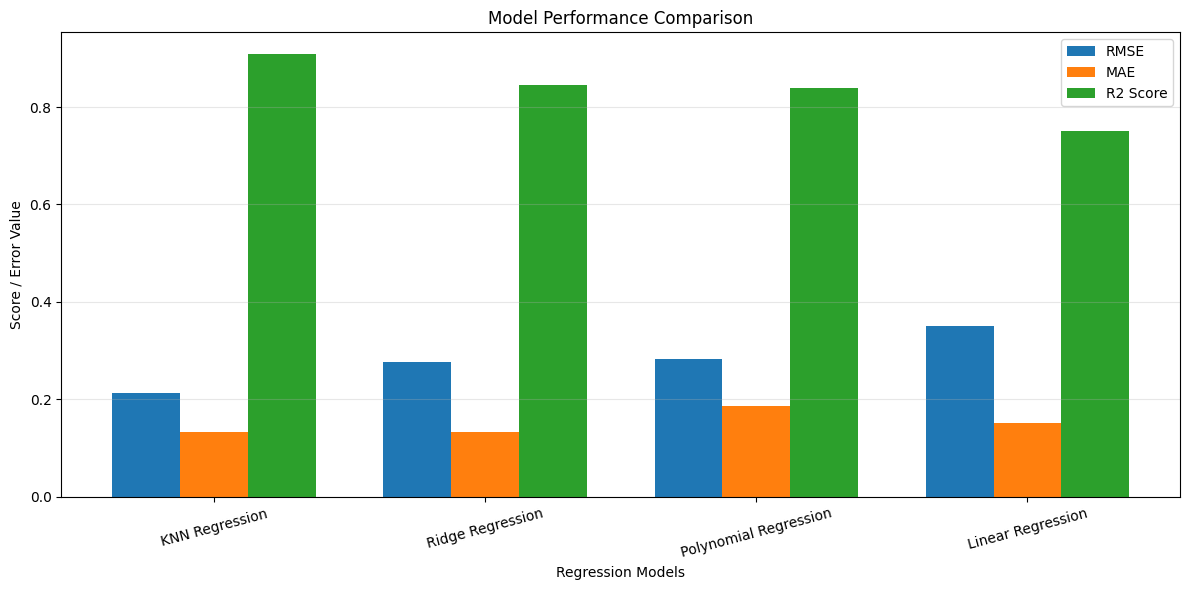

In [10]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

x = np.arange(len(results_df))
width = 0.25

plt.bar(x - width, results_df["RMSE"],
        width, label="RMSE")

plt.bar(x, results_df["MAE"],
        width, label="MAE")

plt.bar(x + width, results_df["R2"],
        width, label="R2 Score")

plt.xlabel("Regression Models")
plt.ylabel("Score / Error Value")
plt.title("Model Performance Comparison")

plt.xticks(x, results_df["Model"], rotation=15)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("model_performance_comparison.png", dpi=300)
plt.show()

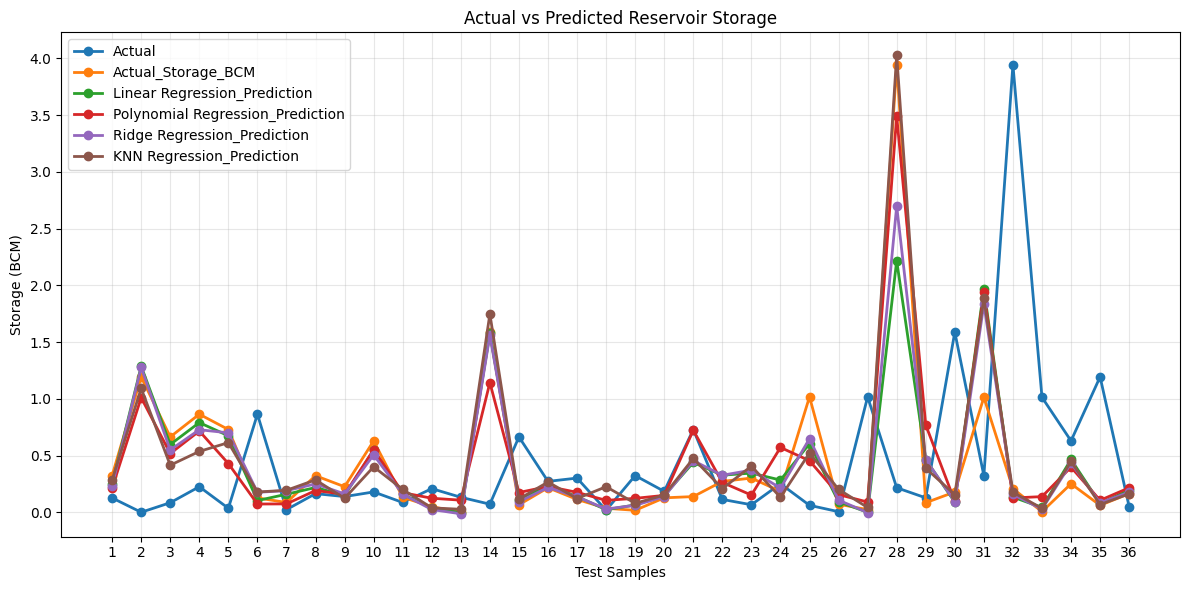

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(y_test) + 1),
    y_test.values,
    marker="o",
    linewidth=2,
    label="Actual"
)

for name, y_pred in predictions.items():
    plt.plot(
        range(1, len(y_pred) + 1),
        y_pred,
        marker="o",
        linewidth=2,
        label=name
    )

plt.xlabel("Test Samples")
plt.ylabel("Storage (BCM)")
plt.title("Actual vs Predicted Reservoir Storage")

plt.xticks(range(1, len(y_test) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()